In [76]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Literal,Annotated
from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage,HumanMessage
import os

In [77]:
from dotenv import load_dotenv
load_dotenv()

True

In [78]:
generator_llm=ChatGroq(model="qwen/qwen3.8-27b",api_key=os.getenv("GROQ_API_KEY"),max_tokens=100)
evaluator_llm=ChatGroq(model="qwen/qwen3.8-27b",api_key=os.getenv("GROQ_API_KEY"),max_tokens=100)
optimizer_llm=ChatGroq(model="qwen/qwen3.8-27b",api_key=os.getenv("GROQ_API_KEY"),max_tokens=100)

In real models,choose diff models for generator,optimizer,evaluator

In [79]:
import operator
# state
# funny and original post on x(twitter)
class TweetState(TypedDict):
    topic:str
    tweet:str
    evaluation:Literal["approved","needs_improvement"]
    feedback:str
    iteration:int
    # evaluator and optimizer kitne loop mai gya
    max_iteration:int
    # break their loop
    
    tweet_history:Annotated[list[str],operator.add]
    feedback_history:Annotated[list[str],operator.add]

In [80]:
from pydantic import BaseModel,Field
class TweetEvaluation(BaseModel):
    evaluation:Literal["approved","needs_improvemnt"]=Field(...,description="Final evaluation feedback")
    feedback:str=Field(...,description="Constructive feedback for tweet")

In [81]:
structured_evaluator_llm=evaluator_llm.with_structured_output(TweetEvaluation)

In [82]:
def generate_tweet(state:TweetState):
    
    # prompt
    messages=[
        SystemMessage(content="You are funny and clever Twitter/X influencer."),
        HumanMessage(content=f"""
        Write a short,1 line original and hilarious tweet on the topic:{state["topic"]}
        Rules:
        -Do not use question answer format.
        -max 280 character
        -use observational humour,irony,sarcasm or cultural refrence.
        -Think in meme logic,punchline or relatable tasks.
        -Use simple day to day english.
                     """)
    ]
    
    # send to generator llm
    response=generator_llm.invoke(messages).content
    
    # return response
    return{
        "tweet":response,"tweet_hostory":[response]
    }

In [83]:
def evaluate_tweet(state: TweetState):
    
    # prompt
    messages=[
        SystemMessage(content="You are ruthless,no laugh given twitter critic.You evaluate tweeets based on humour,originality,virality and tweet format."),
        HumanMessage(content=f"""
        Evaluate the following tweet.
        
        Tweet:{state["tweet"]}
        Use the criteria below to evaluate the tweet.
        1.Originality:Is this fresh or seen hundred times before?
        2.humour-Did it genuinely mak eyou smile,laugh or chuckle?
        3.Punchlines-Is this short,sharp and crisp and scroll stopping?
        4.Virality-Would people reshare or retweet it?
        5.Format-Is this well formed tweet?(not a setup punchline joke,not Q &A joke and under 280 characters.
        
        Auto reject if:
        -Do not use question answer format.
        -max 280 characters
        -It reads like traditional setup-punchline joke.
        -dont end with generic,throwaway lines that weaken the humour.
        
        ##Respond in structured format:
        -evaluation:"approved" or "needs_improvement"
        -feedback-strength and weakness in 1 line
        )
        
        """)
    ]
    
    # model
    response=structured_evaluator_llm.invoke(messages)
    
    return{
        "evaluation":response.evaluation,
        "feedback":response.feedback,
        "feedback_history":[response.feedback]
    }

In [84]:
def optimize_tweet(state:TweetState):
    
    messages=[
        SystemMessage(content="You punch up tweet for virality and humour based on given feedback"),
        HumanMessage(content=f"""
        Improve the tweet base on this feedback.{state["feedback"]}.
        
        Topic:{state["topic"]}
        Original Tweet:{state["tweet"]}
        
        Rewrite it as short,viral worthy tweet.Avoid Q and A style and stay under 200 characters.
                     """)
    ]
    
    response=optimizer_llm.invoke(messages).content
    iteration=state["iteration"]+1
    return{
        "tweet":response,
        "iteration":iteration,
        "tweet_history":[response]
    }

In [85]:
def route_evaluation(state:TweetState):
    
    if state["evaluation"]=="approved" or state["iteration"]>=state["max_iteration"]:
        return "approved"
    else:
        return "needs_improvement"

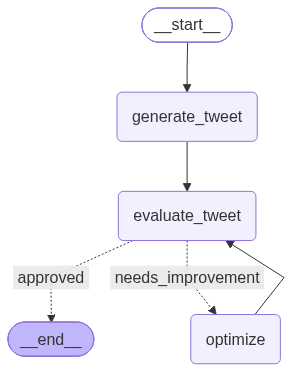

In [86]:
graph=StateGraph(TweetState)

graph.add_node('generate_tweet',generate_tweet)
graph.add_node('evaluate_tweet',evaluate_tweet)
graph.add_node('optimize',optimize_tweet)

graph.add_edge(START,'generate_tweet')
graph.add_edge('generate_tweet','evaluate_tweet')
graph.add_conditional_edges('evaluate_tweet',route_evaluation,{'approved':END,'needs_improvement':'optimize'})
graph.add_edge('optimize','evaluate_tweet')

workflow=graph.compile()
workflow

In [87]:
initial_state={
    "topic":"Indian Railways",
    "iteration":1,
    "max_iteration":5
}
final_state=workflow.invoke(initial_state)
print(final_state)

{'topic': 'Indian Railways', 'tweet': 'Indian Railways trains don’t run late. They wait until you’ve finished your chai, a novel, and started a new life. 🚂☕', 'evaluation': 'approved', 'feedback': 'Strength: The hyperbolic imagery of "starting a new life" during a delay is relatable and visually funny. Weakness: The "chai" +', 'iteration': 2, 'max_iteration': 5, 'tweet_history': ['Indian Railways trains don’t run late. They wait until you’ve finished your chai, a novel, and started a new life. 🚂☕'], 'feedback_history': ['Strength: The core premise of delayed trains and chai is relatable to the target audience. Weakness: The punchline is too long-w', 'Strength: The hyperbolic imagery of "starting a new life" during a delay is relatable and visually funny. Weakness: The "chai" +']}


In [90]:
for tweet in final_state["tweet_history"]:
    print(tweet)

Indian Railways trains don’t run late. They wait until you’ve finished your chai, a novel, and started a new life. 🚂☕
